# Titanic Survival Prediction Analysis

Exploratory analysis of the Titanic passenger dataset to find which variables are related to survival,
followed by chi-square tests of independence and a logistic regression model that predicts whether a passenger survived.

Dataset: [datasciencedojo/datasets – titanic.csv](https://github.com/datasciencedojo/datasets/blob/master/titanic.csv)

## 1. Loading the data

In [1]:
# Import the libraries and load the dataset at the start, so they don't need to be imported again in the cells below.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_URL = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
data = pd.read_csv(DATA_URL)

In [2]:
# Look at the general information to see which variables can be studied in this case.
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 2. Exploratory analysis

### Passenger class (`Pclass`)

Pclass
3    491
1    216
2    184
Name: count, dtype: int64


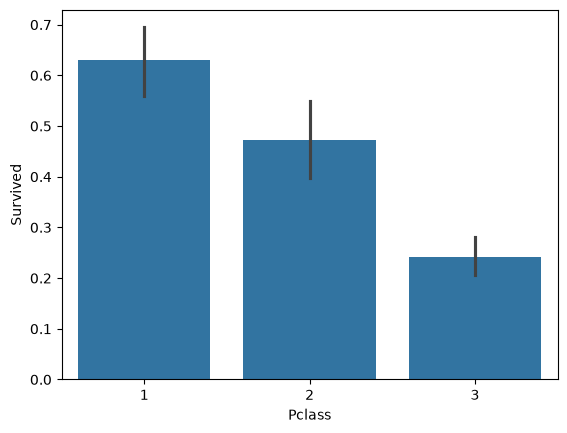

In [3]:
# Distribution of the Pclass variable
print(data['Pclass'].value_counts())

sns.barplot(x='Pclass', y='Survived', data=data)
plt.show()

Even though more than half of the passengers (55%) were travelling in 3rd class, it is the 1st class passengers who have
the highest survival rate (around 63%). 2nd class passengers barely reach 50% (around 47%), still far above the roughly 24%
survival rate of 3rd class passengers. This makes passenger class a factor to take into account when looking at survival.

### Sex (`Sex`)

Sex
male      577
female    314
Name: count, dtype: int64


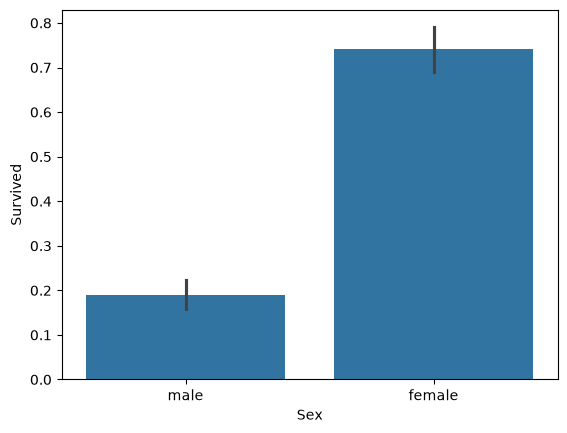

In [4]:
# First the distribution and the plot by sex.
print(data['Sex'].value_counts())

sns.barplot(x='Sex', y='Survived', data=data)
plt.show()

We can see that the survival rate of women (around 74%) is far higher than that of men (around 19%). Women were put
into the lifeboats first during the sinking, which made their survival easier. This large difference in survival rate
makes sex a relevant factor for survival.

### Age (`Age`)

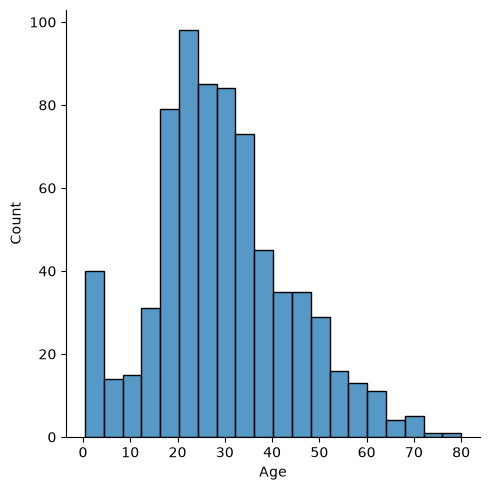

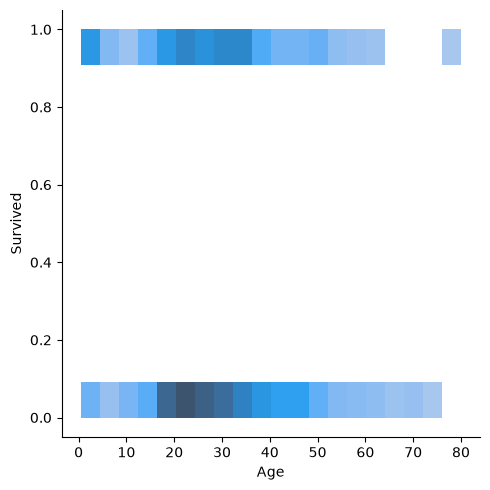

In [5]:
# Age distribution. For the second plot, the colour intensity shows the number of passengers in each cell.
sns.displot(data['Age'])
plt.show()

sns.displot(x='Age', y='Survived', data=data)
plt.show()

Most passengers were in their 20s and 30s (mean age of around 30), and there is also a noticeable group of babies and
young children. These young children had a high survival rate, as did adults between 20 and 40 years old. Age appears
to be related to survival, since survival tends to drop as age increases.

*Note: 177 passengers have no recorded age and are left out of these plots.*

### Port of embarkation (`Embarked`)

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


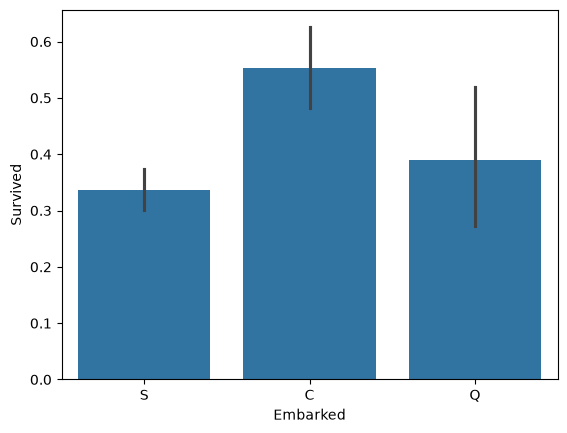

In [6]:
# Distribution by port of embarkation; each port is identified by its initial.
print(data['Embarked'].value_counts())

sns.barplot(x='Embarked', y='Survived', data=data)
plt.show()

This plot shows the port where passengers boarded the Titanic: **S** is Southampton, **C** is Cherbourg and **Q** is
Queenstown. Cherbourg has the highest survival rate (around 55%), even though far fewer passengers boarded there than in
Southampton. Southampton, where most passengers (72%) boarded, has the lowest survival rate (around 34%), and
Queenstown, the port with the fewest passengers, sits in between (around 39%).

### Siblings / spouses aboard (`SibSp`)

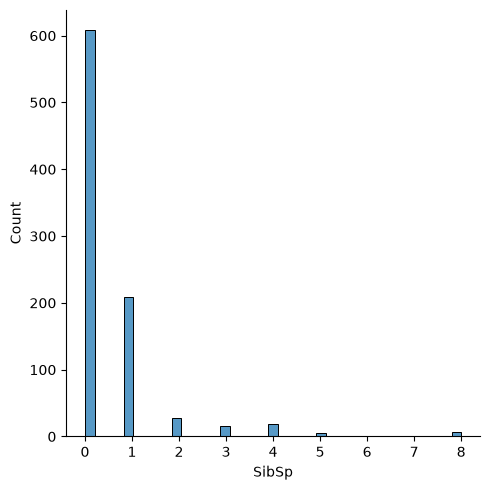

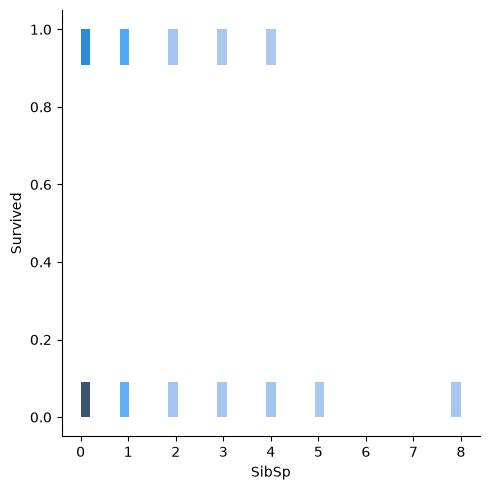

In [7]:
# Number of siblings/spouses each passenger had aboard
sns.displot(data['SibSp'])
plt.show()

sns.displot(x='SibSp', y='Survived', data=data)
plt.show()

A large majority of passengers travelled without siblings or a spouse, followed by those travelling with just one.
Survival does not change much with this variable, although passengers with exactly one sibling/spouse aboard did
somewhat better than those travelling alone.

### Parents / children aboard (`Parch`)

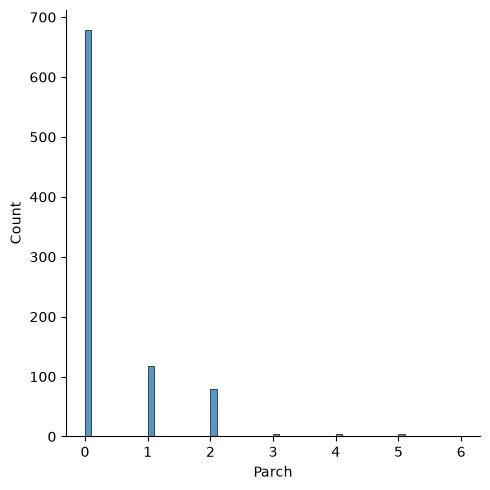

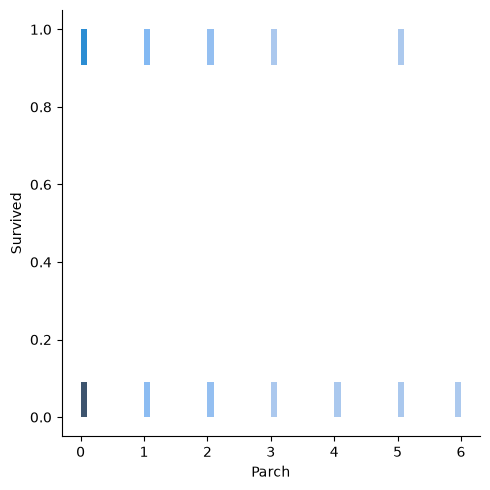

In [8]:
# This plot describes the family unit (parents/children) of each passenger
sns.displot(data['Parch'])
plt.show()

sns.displot(x='Parch', y='Survived', data=data)
plt.show()

`Parch` is the number of parents/children each passenger had aboard. Most passengers did not travel with parents or
children; however, among those who did, the survival rate held up.

### Ticket fare (`Fare`)

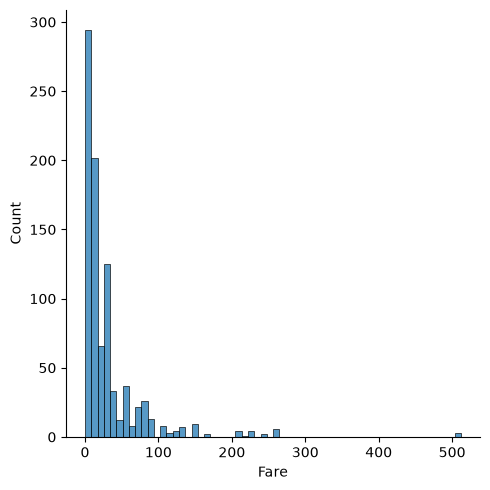

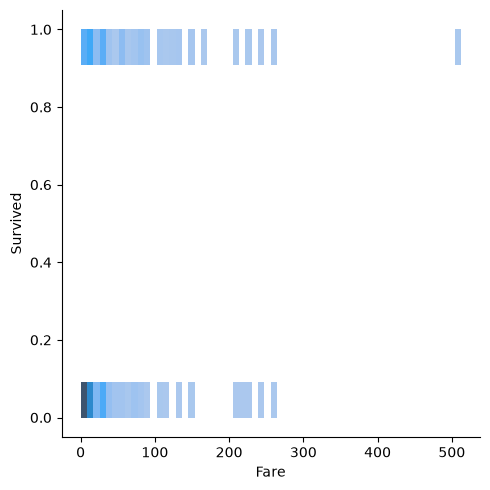

In [9]:
# Distribution of the ticket fare
sns.displot(data['Fare'])
plt.show()

sns.displot(x='Fare', y='Survived', data=data)
plt.show()

The average ticket fare is around 32 (the median is around 14, since a few very expensive tickets pull the mean up).
We can also see that as ticket prices increase, so does the survival rate, reaching around 60%. This variable is
closely related to `Pclass`.

## 3. Chi-square tests

Now I will look at the relationship between each variable and survival using the chi-square test of independence and its p-value.

In [10]:
import scipy.stats as stats  # Library for the statistical analysis

# To check the relationship between each variable and survival, run a chi-square test and get its p-value.
def run_chi2_test(variable, data):
    contingency = pd.crosstab(data[variable], data['Survived'])
    chi2, pval, dof, expected = stats.chi2_contingency(contingency.values)

    print(f"\nChi-square test for {variable} and Survived:")
    print(f"  Chi-square: {chi2:.2f}")
    print(f"  p-value: {pval:.3g}")

# Variables relevant to this study
variables_to_analyze = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Embarked', 'Fare']

for variable in variables_to_analyze:
    run_chi2_test(variable, data)


Chi-square test for Pclass and Survived:
  Chi-square: 102.89
  p-value: 4.55e-23

Chi-square test for Sex and Survived:
  Chi-square: 260.72
  p-value: 1.2e-58

Chi-square test for Age and Survived:
  Chi-square: 104.16
  p-value: 0.101

Chi-square test for SibSp and Survived:
  Chi-square: 37.27
  p-value: 1.56e-06

Chi-square test for Parch and Survived:
  Chi-square: 27.93
  p-value: 9.7e-05

Chi-square test for Embarked and Survived:
  Chi-square: 26.49
  p-value: 1.77e-06

Chi-square test for Fare and Survived:
  Chi-square: 425.81
  p-value: 1.16e-11


Despite the first impressions from the plots above, the p-values give a clearer picture. Taking the usual
significance level of 0.05, a p-value **below** 0.05 means we can reject the hypothesis that the variable and survival are independent:

- **Passenger class, sex, port of embarkation, siblings/spouses, parents/children and ticket fare** all have p-values well
  below 0.05, so they are significantly related to a passenger's survival. Sex and passenger class show by far the strongest relationship.
- **Age** is the only variable with a p-value above 0.05 (≈ 0.10), so this test alone does not let us claim a relationship
  between age and survival.

*Note: `Age` and `Fare` are continuous variables, and here every distinct value is treated as its own category. Many cells of
their contingency tables have very few passengers, so their chi-square results should be read with caution; grouping them
into ranges (e.g. age groups) would give a more reliable test.*

## 4. Logistic regression

In [11]:
# Now train a logistic regression model to predict survival

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Work on a copy so the original dataset used in the cells above is not modified
model_data = data.copy()

model_data['Age'] = model_data['Age'].fillna(model_data['Age'].median())
model_data['Embarked'] = model_data['Embarked'].fillna(model_data['Embarked'].mode()[0])
model_data['Sex'] = model_data['Sex'].map({'male': 0, 'female': 1})  # Encode categorical variables

model_data = pd.get_dummies(model_data, columns=['Embarked'], drop_first=True)

# Select the features used in the model
features = ['Pclass', 'Sex', 'SibSp', 'Parch', 'Embarked_Q', 'Embarked_S', 'Fare', 'Age']
x = model_data[features]
y = model_data['Survived']

x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=42)  # Fixed seed so results are reproducible

model = LogisticRegression(max_iter=2000)  # High iteration limit to make sure the model converges
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.3f}")  # Proportion of correct predictions
print("Confusion Matrix:")  # Breakdown of the classification performance
print(conf_matrix)
print("Classification Report:")
print(class_report)

Accuracy: 0.807
Confusion Matrix:
[[115  19]
 [ 24  65]]
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       134
           1       0.77      0.73      0.75        89

    accuracy                           0.81       223
   macro avg       0.80      0.79      0.80       223
weighted avg       0.81      0.81      0.81       223



The model correctly predicts survival for about **81%** of the passengers in the test set. It is better at identifying
passengers who did not survive (recall 0.86) than those who did (recall 0.73), which is expected since there are more
non-survivors in the data.